# MI-Guided Temporal & Hybrid Soft-Sensor Pipeline for Low-Cost BOD Prediction
**Input Sensors (Strictly 3 Raw Hardware Channels):**
1. `TDS (ppm)` — Total Dissolved Solids (via Electrical Conductivity)
2. `Turbidity (NTU)` — Nephelometric Turbidity
3. `Temperature (cel)` — Water Temperature (°C)

**Target Variable:** `Biochemical Oxygen Demand (mg/l)`

---
### Implemented Research Methodologies (Experiments E1–E9)
* **E1 – E3 (Baseline Nonlinear Models on Raw 3 Features):** Random Forest, SVR (RBF), and Gradient Boosting (XGBoost / HistGradientBoosting).
* **E4 (Nonlinear Domain Feature Engineering & Compensation — Khamis et al., 2017):** Cross-sensor interactions (`TDS × Temp`, `Turbidity × Temp`, `TDS × Turbidity`), temperature-compensated TDS, suspended-to-dissolved solids ratio (`Turbidity / TDS`), and optical scattering transforms (`log1p(Turbidity)`).
* **E5 (Causal Temporal Feature Engineering — Bi-LSTM / Soft-Sensor Literature, 2024):** Per-location chronological lags (`t-1`, `t-2`, `t-3`), rolling mean, rolling std, rolling min/max, and 1st-order rate of change (`Δ/dt`).
* **E6 (KNN Mutual Information Feature Selection — 2022):** Non-parametric `mutual_info_regression` (KSG k-NN estimator) + greedy mRMR redundancy filtering computed **strictly inside the training split** to prevent data leakage.
* **E7 (Latent Feature Extraction — PLSR):** Partial Least Squares Regression extracting target-aware latent components.
* **E8 (Hybrid Stacking Regressor — Nafsin & Li, 2022):** Hybrid `Random Forest + GBDT + SVR (RBF)` Stacking Regressor with Ridge meta-learner.
* **E9 (Regime-Specific Soft Sensor):** Unsupervised K-Means water-quality regime clustering paired with regime-specialized local models.
* **Validation Protocols:** Both **Chronological Split** (time-series forecasting validity) and **Leave-One-Location-Out Spatial Split** (generalization to unseen water bodies).

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import mahalanobis

from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import mutual_info_regression
from sklearn.cross_decomposition import PLSRegression
from sklearn.cluster import KMeans
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, StackingRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, accuracy_score, f1_score
import joblib

try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("XGBoost not installed; using HistGradientBoostingRegressor (equivalent GBDT implementation).")

try:
    import shap
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
    import shap

np.random.seed(42)
DATA_PATH = 'Realistic_ESP32_Water_Quality_Dataset-v2.csv'
print(f"Environment initialized. SHAP version: {shap.__version__}")

Environment initialized. SHAP version: 0.54.1


In [ ]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv('/content/Realistic_ESP32_Water_Quality_Dataset-v2.csv')
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df = df.sort_values(['Location', 'Timestamp']).reset_index(drop=True)

# Strictly isolate ONLY the 3 low-cost ESP32 sensor columns + metadata + target
RAW_FEATURES = ['TDS (ppm)', 'Turbidity (NTU)', 'Temperature (cel)']
TARGET_COL = 'Biochemical Oxygen Demand (mg/l)'
META_COLS = ['Timestamp', 'Location']

df_sensor = df[META_COLS + RAW_FEATURES + [TARGET_COL]].copy()

print(f"Loaded {len(df_sensor):,} rows.")
print(f"Strict Input Sensors: {RAW_FEATURES}")
print(f"Locations: {df_sensor['Location'].unique().tolist()}")
df_sensor.head()

Loaded 100,000 rows.
Strict Input Sensors: ['TDS (ppm)', 'Turbidity (NTU)', 'Temperature (cel)']
Locations: ['L1', 'L2', 'L3', 'L4', 'L5']


,Timestamp,Location,TDS (ppm),Turbidity (NTU),Temperature (cel),Biochemical Oxygen Demand (mg/l)
0,2026-01-01 00:02:00,L1,483.53,363.59,23.83,11.48
1,2026-01-01 00:06:00,L1,346.04,85.22,23.14,6.42
2,2026-01-01 00:08:00,L1,498.67,4.69,23.30,5.24
3,2026-01-01 00:09:00,L1,474.80,46.75,30.68,6.03
4,2026-01-01 00:15:00,L1,218.31,96.11,22.45,7.59


### Real-World BOD & Hydrological Soft-Sensor Evaluation Metrics
In environmental engineering and wastewater soft-sensing literature, $R^2$ alone can be misleading because it is insensitive to additive or proportional bias. This pipeline evaluates models using:
1. **Nash-Sutcliffe Efficiency ($	ext{NSE}$):** Standard hydrological goodness-of-fit ($-\infty$ to $1.0$; $>0.75$ = Very Good, $0.65	ext{–}0.75$ = Good, $0.50	ext{–}0.65$ = Satisfactory).
2. **Kling-Gupta Efficiency ($	ext{KGE}$):** Decomposes error into linear correlation ($r$), variability ratio ($lpha = \sigma_{	ext{pred}}/\sigma_{	ext{obs}}$), and mean bias ratio ($eta = \mu_{	ext{pred}}/\mu_{	ext{obs}}$). Optimal = $1.0$.
3. **Percent Bias ($	ext{PBIAS}$):** Measures systematic over- or under-prediction ($0\%$ optimal; within $\pm 15\%$ considered good for water-quality modeling).
4. **Willmott's Index of Agreement ($d$):** Bounded $[0, 1]$ metric sensitive to differences in observed and predicted means and variances.
5. **Regulatory Effluent Class Accuracy & Macro-F1 (CPCB / EPA BOD Thresholds):**
   * **Class 0 (Clean / Bathing / Raw Drinking Source):** $	ext{BOD} \le 3.0	ext{ mg/L}$
   * **Class 1 (Inland Surface Water Discharge Standard):** $3.0 < 	ext{BOD} \le 10.0	ext{ mg/L}$
   * **Class 2 (Treated STP Effluent Limit):** $10.0 < 	ext{BOD} \le 30.0	ext{ mg/L}$
   * **Class 3 (Severe Untreated Wastewater):** $	ext{BOD} > 30.0	ext{ mg/L}$

In [ ]:
def bod_regulatory_class(bod_array):
    """Maps continuous BOD (mg/L) into real-world environmental regulatory tiers."""
    return np.digitize(bod_array, bins=[3.0, 10.0, 30.0])

def evaluate_bod_predictions(y_true, y_pred, model_name="Model"):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    # Standard ML Regression Metrics
    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / np.maximum(y_true, 1e-6))) * 100.0

    # Nash-Sutcliffe Efficiency (NSE)
    nse = 1.0 - (np.sum((y_true - y_pred) ** 2) / np.sum((y_true - np.mean(y_true)) ** 2))

    # Kling-Gupta Efficiency (KGE)
    r = np.corrcoef(y_true, y_pred)[0, 1] if np.std(y_pred) > 0 else 0.0
    alpha = np.std(y_pred) / np.std(y_true)
    beta = np.mean(y_pred) / np.mean(y_true)
    kge = 1.0 - np.sqrt((r - 1.0) ** 2 + (alpha - 1.0) ** 2 + (beta - 1.0) ** 2)

    # Percent Bias (PBIAS %)
    pbias = 100.0 * np.sum(y_pred - y_true) / np.sum(y_true)

    # Willmott's Index of Agreement (d)
    num = np.sum((y_true - y_pred) ** 2)
    den = np.sum((np.abs(y_pred - np.mean(y_true)) + np.abs(y_true - np.mean(y_true))) ** 2)
    willmott_d = 1.0 - (num / den)

    # Regulatory Tier Classification Accuracy & Macro-F1
    true_cls = bod_regulatory_class(y_true)
    pred_cls = bod_regulatory_class(y_pred)
    reg_acc = accuracy_score(true_cls, pred_cls) * 100.0
    reg_f1 = f1_score(true_cls, pred_cls, average='macro')

    return {
        'Model': model_name,
        'MAE (mg/L)': round(mae, 3),
        'RMSE (mg/L)': round(rmse, 3),
        'R2': round(r2, 4),
        'MAPE (%)': round(mape, 2),
        'NSE': round(nse, 4),
        'KGE': round(kge, 4),
        'PBIAS (%)': round(pbias, 2),
        'Willmott_d': round(willmott_d, 4),
        'Reg_Class_Acc (%)': round(reg_acc, 2),
        'Reg_Macro_F1': round(reg_f1, 4)
    }

In [ ]:
def engineer_soft_sensor_features(data, window_steps=6):
    """
    Extracts nonlinear domain interaction features (Khamis et al., 2017) and
    causal temporal history features (Bi-LSTM/soft-sensor literature, 2024)
    strictly from TDS, Turbidity, and Temperature.
    """
    df_feat = data.copy()

    tds = df_feat['TDS (ppm)']
    turb = df_feat['Turbidity (NTU)']
    temp = df_feat['Temperature (cel)']

    # --- A. Physical / Compensation Interaction Features ---
    df_feat['TDS_x_Temp'] = tds * temp
    df_feat['Turb_x_Temp'] = turb * temp
    df_feat['TDS_x_Turb'] = tds * turb

    # Temperature-compensated TDS (reversing linear thermal drift to isolate ionic load)
    temp_comp_factor = 1.0 + 0.02 * (temp - 25.0)
    df_feat['TDS_TempCompensated'] = tds / temp_comp_factor

    # Suspended-to-Dissolved Solids Ratio (separates organic particulate load from mineral salinity)
    df_feat['Turb_to_TDS_Ratio'] = turb / (tds + 1.0)

    # Nonlinear optical scattering & microbial metabolic transforms
    df_feat['Log_Turbidity'] = np.log1p(turb)
    df_feat['Sqrt_Turbidity'] = np.sqrt(turb)
    df_feat['Log_TDS'] = np.log1p(tds)
    df_feat['Temp_Anomaly_25C'] = np.maximum(0.0, temp - 25.0)

    # --- B. Causal Temporal Features (Grouped by Location, Zero Future Leakage) ---
    df_feat = df_feat.sort_values(['Location', 'Timestamp']).reset_index(drop=True)
    grp = df_feat.groupby('Location')

    for col, short in [('TDS (ppm)', 'TDS'), ('Turbidity (NTU)', 'Turb'), ('Temperature (cel)', 'Temp')]:
        df_feat[f'{short}_lag1'] = grp[col].shift(1)
        df_feat[f'{short}_lag2'] = grp[col].shift(2)
        df_feat[f'{short}_lag3'] = grp[col].shift(3)
        df_feat[f'{short}_diff1'] = grp[col].diff(1)

        rolling_obj = grp[col].rolling(window=window_steps, min_periods=1)
        df_feat[f'{short}_roll_mean'] = rolling_obj.mean().reset_index(level=0, drop=True)
        df_feat[f'{short}_roll_std'] = rolling_obj.std().fillna(0.0).reset_index(level=0, drop=True)
        df_feat[f'{short}_roll_min'] = rolling_obj.min().reset_index(level=0, drop=True)
        df_feat[f'{short}_roll_max'] = rolling_obj.max().reset_index(level=0, drop=True)

    df_feat = df_feat.dropna().reset_index(drop=True)
    return df_feat

df_engineered = engineer_soft_sensor_features(df_sensor, window_steps=6)
ALL_ENGINEERED_FEATURES = [c for c in df_engineered.columns if c not in META_COLS + [TARGET_COL]]
print(f"Engineered {len(ALL_ENGINEERED_FEATURES)} features from the 3 raw sensors.")

Engineered 36 features from the 3 raw sensors.


In [ ]:
# Chronological split: first 80% timestamps for training, last 20% for testing
cutoff_time = df_engineered['Timestamp'].quantile(0.80)
train_df = df_engineered[df_engineered['Timestamp'] <= cutoff_time].reset_index(drop=True)
test_df = df_engineered[df_engineered['Timestamp'] > cutoff_time].reset_index(drop=True)

print(f"Chronological Train rows: {len(train_df):,} | Test rows: {len(test_df):,}")

def select_features_knn_mi(X_train, y_train, top_k=12, redundancy_penalty=0.30, sample_cap=15000):
    """
    Computes k-NN Mutual Information (KSG estimator, k=5) between candidate features and BOD,
    compares against linear Pearson |r|, and applies greedy mRMR redundancy filtering.
    """
    if len(X_train) > sample_cap:
        idx = np.random.choice(len(X_train), size=sample_cap, replace=False)
        X_sub = X_train.iloc[idx]
        y_sub = y_train.iloc[idx]
    else:
        X_sub, y_sub = X_train, y_train

    mi_scores = mutual_info_regression(X_sub, y_sub, n_neighbors=5, random_state=42)
    pearson_abs = np.abs(X_sub.apply(lambda col: col.corr(y_sub)))

    stats_df = pd.DataFrame({
        'Feature': X_train.columns,
        'KNN_MI': mi_scores,
        'Abs_Pearson_r': pearson_abs.values
    }).sort_values('KNN_MI', ascending=False).reset_index(drop=True)

    # Greedy mRMR (Minimum Redundancy Maximum Relevance) selection
    selected = []
    candidates = list(stats_df['Feature'])
    mi_map = dict(zip(stats_df['Feature'], stats_df['KNN_MI']))
    corr_matrix = X_sub.corr().abs()

    while len(selected) < min(top_k, len(candidates)):
        best_feat = None
        best_score = -np.inf
        for feat in candidates:
            if feat in selected:
                continue
            relevance = mi_map[feat]
            redundancy = np.mean([corr_matrix.loc[feat, s] for s in selected]) if selected else 0.0
            score = relevance - redundancy_penalty * redundancy
            if score > best_score:
                best_score = score
                best_feat = feat
        selected.append(best_feat)

    return selected, stats_df

SELECTED_MI_FEATURES, mi_report = select_features_knn_mi(
    train_df[ALL_ENGINEERED_FEATURES],
    train_df[TARGET_COL],
    top_k=12,
    redundancy_penalty=0.30
)

print("\nTop 15 Features by KNN Mutual Information vs. Linear Pearson |r|:")
print(mi_report.head(15).to_string(index=False))
print(f"\nSelected {len(SELECTED_MI_FEATURES)} Redundancy-Filtered Features:\n{SELECTED_MI_FEATURES}")

Chronological Train rows: 79,988 | Test rows: 19,997

Top 15 Features by KNN Mutual Information vs. Linear Pearson |r|:
            Feature   KNN_MI  Abs_Pearson_r
      Log_Turbidity 1.580248       0.931259
     Sqrt_Turbidity 1.579548       0.984434
        Turb_x_Temp 1.575941       0.950163
    Turbidity (NTU) 1.575769       0.959818
         TDS_x_Turb 1.491828       0.918526
  Turb_to_TDS_Ratio 0.775229       0.866351
         Turb_diff1 0.704084       0.680198
         TDS_x_Temp 0.491048       0.797477
            Log_TDS 0.490075       0.731975
          TDS (ppm) 0.489113       0.795204
TDS_TempCompensated 0.442542       0.768291
          TDS_diff1 0.214405       0.566905
      Turb_roll_max 0.194697       0.289414
      Turb_roll_std 0.163319       0.280835
  Temperature (cel) 0.153460       0.485085

Selected 12 Redundancy-Filtered Features:
['Log_Turbidity', 'Turb_x_Temp', 'Turbidity (NTU)', 'Sqrt_Turbidity', 'TDS_x_Turb', 'Turb_to_TDS_Ratio', 'Turb_diff1', 'Log_TDS', 'TD

In [ ]:
SVR_TRAIN_CAP = 15000
svr_idx = np.random.choice(len(train_df), size=min(SVR_TRAIN_CAP, len(train_df)), replace=False)

y_train = train_df[TARGET_COL].values
y_test = test_df[TARGET_COL].values

results = []
predictions_store = {}

# E1: Random Forest on Raw 3 Sensors
rf_raw = RandomForestRegressor(n_estimators=120, max_depth=16, min_samples_leaf=5, n_jobs=-1, random_state=42)
rf_raw.fit(train_df[RAW_FEATURES], y_train)
pred_e1 = rf_raw.predict(test_df[RAW_FEATURES])
results.append(evaluate_bod_predictions(y_test, pred_e1, "E1: RF (Raw 3 Sensors)"))
predictions_store["E1: RF (Raw 3)"] = pred_e1

# E2: SVR (RBF) on Raw 3 Sensors
svr_raw = Pipeline([('scaler', RobustScaler()), ('svr', SVR(kernel='rbf', C=10.0, epsilon=0.2))])
svr_raw.fit(train_df[RAW_FEATURES].iloc[svr_idx], y_train[svr_idx])
pred_e2 = svr_raw.predict(test_df[RAW_FEATURES])
results.append(evaluate_bod_predictions(y_test, pred_e2, "E2: SVR-RBF (Raw 3 Sensors)"))

# E3: Gradient Boosting (XGBoost / HistGBDT) on Raw 3 Sensors
gb_raw = XGBRegressor(n_estimators=200, max_depth=6, learning_rate=0.06, random_state=42, n_jobs=-1) if HAS_XGB else HistGradientBoostingRegressor(max_iter=200, max_depth=6, learning_rate=0.06, random_state=42)
gb_raw.fit(train_df[RAW_FEATURES], y_train)
pred_e3 = gb_raw.predict(test_df[RAW_FEATURES])
results.append(evaluate_bod_predictions(y_test, pred_e3, "E3: GBDT (Raw 3 Sensors)"))

# E4: Domain Interaction & Compensation Features Only (Khamis et al. adaptation)
DOMAIN_FEATURES = RAW_FEATURES + [
    'TDS_x_Temp', 'Turb_x_Temp', 'TDS_x_Turb', 'TDS_TempCompensated',
    'Turb_to_TDS_Ratio', 'Log_Turbidity', 'Sqrt_Turbidity', 'Log_TDS', 'Temp_Anomaly_25C'
]
gb_domain = XGBRegressor(n_estimators=250, max_depth=7, learning_rate=0.05, random_state=42, n_jobs=-1) if HAS_XGB else HistGradientBoostingRegressor(max_iter=250, max_depth=7, learning_rate=0.05, random_state=42)
gb_domain.fit(train_df[DOMAIN_FEATURES], y_train)
pred_e4 = gb_domain.predict(test_df[DOMAIN_FEATURES])
results.append(evaluate_bod_predictions(y_test, pred_e4, "E4: GBDT (Domain Compensation)"))

# E5: All Temporal + Domain Engineered Features (36 features)
gb_all = XGBRegressor(n_estimators=250, max_depth=7, learning_rate=0.05, random_state=42, n_jobs=-1) if HAS_XGB else HistGradientBoostingRegressor(max_iter=250, max_depth=7, learning_rate=0.05, random_state=42)
gb_all.fit(train_df[ALL_ENGINEERED_FEATURES], y_train)
pred_e5 = gb_all.predict(test_df[ALL_ENGINEERED_FEATURES])
results.append(evaluate_bod_predictions(y_test, pred_e5, "E5: GBDT (All Temporal + Domain)"))

# E6: KNN-MI Selected Features (12 mRMR features)
gb_mi = XGBRegressor(n_estimators=250, max_depth=7, learning_rate=0.05, random_state=42, n_jobs=-1) if HAS_XGB else HistGradientBoostingRegressor(max_iter=250, max_depth=7, learning_rate=0.05, random_state=42)
gb_mi.fit(train_df[SELECTED_MI_FEATURES], y_train)
pred_e6 = gb_mi.predict(test_df[SELECTED_MI_FEATURES])
results.append(evaluate_bod_predictions(y_test, pred_e6, "E6: GBDT (KNN-MI Top-12)"))
predictions_store["E6: GBDT (KNN-MI)"] = pred_e6

# E7: Latent Feature Extraction via Partial Least Squares Regression (PLSR)
plsr_pipe = Pipeline([('scaler', StandardScaler()), ('pls', PLSRegression(n_components=6))])
plsr_pipe.fit(train_df[SELECTED_MI_FEATURES], y_train)
pred_e7 = plsr_pipe.predict(test_df[SELECTED_MI_FEATURES]).ravel()
results.append(evaluate_bod_predictions(y_test, pred_e7, "E7: PLSR Latent (KNN-MI Top-12)"))

# E8: Hybrid Stacking Regressor (RF + GBDT + SVR-RBF with Ridge Meta-Learner)
hybrid_stack = StackingRegressor(
    estimators=[
        ('rf', RandomForestRegressor(n_estimators=80, max_depth=14, min_samples_leaf=5, n_jobs=-1, random_state=42)),
        ('gb', HistGradientBoostingRegressor(max_iter=180, max_depth=6, learning_rate=0.05, random_state=42)),
        ('svr', Pipeline([('scaler', RobustScaler()), ('svr', SVR(kernel='rbf', C=10.0, epsilon=0.2))]))
    ],
    final_estimator=Ridge(alpha=1.0),
    cv=3,
    n_jobs=-1
)
hybrid_stack.fit(train_df[SELECTED_MI_FEATURES].iloc[svr_idx], y_train[svr_idx])
pred_e8 = hybrid_stack.predict(test_df[SELECTED_MI_FEATURES])
results.append(evaluate_bod_predictions(y_test, pred_e8, "E8: Hybrid RF+GBDT+SVR Stack"))
predictions_store["E8: Hybrid Stack"] = pred_e8

results_df = pd.DataFrame(results)
print("=== CHRONOLOGICAL TEST SET BENCHMARK (ALL METRICS) ===")
display(results_df)

=== CHRONOLOGICAL TEST SET BENCHMARK (ALL METRICS) ===


,Model,MAE (mg/L),RMSE (mg/L),R2,MAPE (%),NSE,KGE,PBIAS (%),Willmott_d,Reg_Class_Acc (%),Reg_Macro_F1
0,E1: RF (Raw 3 Sensors),0.989,1.243,0.9772,14.43,0.9772,0.9848,-0.18,0.9942,90.47,0.7292
1,E2: SVR-RBF (Raw 3 Sensors),0.973,1.222,0.9779,14.47,0.9779,0.9833,0.02,0.9944,90.49,0.7094
2,E3: GBDT (Raw 3 Sensors),0.968,1.217,0.9781,14.19,0.9781,0.9849,-0.15,0.9944,90.52,0.7227
3,E4: GBDT (Domain Compensation),0.969,1.219,0.9780,14.22,0.9780,0.9849,-0.16,0.9944,90.67,0.7253
4,E5: GBDT (All Temporal + Domain),0.969,1.220,0.9780,14.21,0.9780,0.9849,-0.15,0.9944,90.60,0.7281
5,E6: GBDT (KNN-MI Top-12),0.971,1.220,0.9780,14.24,0.9780,0.9850,-0.16,0.9944,90.66,0.7269
6,E7: PLSR Latent (KNN-MI Top-12),0.990,1.249,0.9769,14.58,0.9769,0.9842,-0.15,0.9941,90.24,0.7707
7,E8: Hybrid RF+GBDT+SVR Stack,0.967,1.217,0.9781,14.20,0.9781,0.9858,-0.18,0.9944,90.51,0.7257


### Explainable AI (SHAP) & Calibrated Per-Prediction Confidence Intervals
To make soft-sensor BOD predictions trustworthy for real-time water quality monitoring, we add:
1. **Conformalized Quantile XGBoost (`gb_mi_lower`, `gb_mi_upper`)**: Predicts 5th and 95th conditional percentiles and calibrates them on a held-out chronological slice via Split Conformal Prediction to guarantee **90% empirical interval coverage**, combined with a Mahalanobis out-of-distribution check to produce a **0–100% Confidence Score** per reading.
2. **SHAP Explainability (`shap.TreeExplainer`)**: Computes global feature attributions and per-sample driver breakdowns showing how each sensor feature pushes individual BOD predictions up or down.

In [ ]:
# === CONFORMALIZED QUANTILE REGRESSION FOR PER-PREDICTION CONFIDENCE ===
# Split train_df chronologically into proper-train (85%) and calibration (15%)
cal_split = int(len(train_df) * 0.85)
X_prop = train_df[SELECTED_MI_FEATURES].iloc[:cal_split]
y_prop = y_train[:cal_split]
X_cal = train_df[SELECTED_MI_FEATURES].iloc[cal_split:]
y_cal = y_train[cal_split:]

ALPHA = 0.10  # Target 90% prediction interval coverage

if HAS_XGB:
    gb_mi_lower = XGBRegressor(
        n_estimators=250, max_depth=7, learning_rate=0.05,
        objective='reg:quantileerror', quantile_alpha=ALPHA / 2,
        random_state=42, n_jobs=-1
    )
    gb_mi_upper = XGBRegressor(
        n_estimators=250, max_depth=7, learning_rate=0.05,
        objective='reg:quantileerror', quantile_alpha=1.0 - (ALPHA / 2),
        random_state=42, n_jobs=-1
    )
else:
    gb_mi_lower = HistGradientBoostingRegressor(
        max_iter=250, max_depth=7, learning_rate=0.05,
        loss='quantile', quantile=ALPHA / 2, random_state=42
    )
    gb_mi_upper = HistGradientBoostingRegressor(
        max_iter=250, max_depth=7, learning_rate=0.05,
        loss='quantile', quantile=1.0 - (ALPHA / 2), random_state=42
    )

gb_mi_lower.fit(X_prop, y_prop)
gb_mi_upper.fit(X_prop, y_prop)

# Compute Split Conformal non-conformity scores on calibration set
cal_low = gb_mi_lower.predict(X_cal)
cal_high = gb_mi_upper.predict(X_cal)
cal_scores = np.maximum(cal_low - y_cal, y_cal - cal_high)
conformal_q_hat = float(np.quantile(cal_scores, 1.0 - ALPHA))

# Reference scale for normalizing confidence %
cal_widths = np.maximum(0.1, (cal_high + conformal_q_hat) - np.maximum(0.0, cal_low - conformal_q_hat))
ref_max_width = float(np.quantile(cal_widths, 0.98))
typical_rmse = float(root_mean_squared_error(y_cal, gb_mi.predict(X_cal)))

# Feature distribution stats for Out-of-Distribution (OOD) confidence penalty
train_feat_mean = train_df[SELECTED_MI_FEATURES].mean().values
train_feat_cov_inv = np.linalg.pinv(np.cov(train_df[SELECTED_MI_FEATURES].values, rowvar=False))
cal_maha = [mahalanobis(row, train_feat_mean, train_feat_cov_inv) for row in X_cal.values]
maha_95 = float(np.percentile(cal_maha, 95))

# Verify empirical coverage on unseen test set
test_low = np.maximum(0.0, gb_mi_lower.predict(test_df[SELECTED_MI_FEATURES]) - conformal_q_hat)
test_high = gb_mi_upper.predict(test_df[SELECTED_MI_FEATURES]) + conformal_q_hat
empirical_coverage = np.mean((y_test >= test_low) & (y_test <= test_high)) * 100.0

print(f"Conformal Calibration Offset (q_hat): ±{conformal_q_hat:.3f} mg/L")
print(f"Target Coverage: {(1 - ALPHA)*100:.0f}% | Empirical Test Coverage: {empirical_coverage:.2f}%")

Conformal Calibration Offset (q_hat): ±-0.764 mg/L
Target Coverage: 90% | Empirical Test Coverage: 90.03%


=== SAMPLE TEST PREDICTIONS WITH CONFIDENCE & LOCAL SHAP EXPLANATIONS ===


,Timestamp,Location,TDS (ppm),Turbidity (NTU),Temperature (cel),Pred_BOD (mg/L),Actual_BOD (mg/L),90%_CI_Low,90%_CI_High,Uncertainty (±mg/L),Confidence (%),Confidence_Tier,Top_SHAP_Drivers (mg/L impact)
0,2026-02-25 13:30:00,L1,200.32,49.73,22.13,4.84,4.51,3.03,10.890000,3.93,50.2,Low,"Turb_x_Temp (-5.16), Log_Turbidity (-1.82), TDS_x_Turb (-1.24)"
1,2026-03-05 05:16:00,L1,435.72,315.06,23.36,11.39,10.30,9.40,15.830000,3.22,78.7,Medium,"Log_Turbidity (-1.34), Turb_x_Temp (-0.70), TDS_x_Turb (+0.64)"
2,2026-02-27 04:34:00,L2,325.76,93.76,21.22,6.52,6.42,4.81,12.320000,3.76,61.3,Medium,"Turb_x_Temp (-4.51), Log_Turbidity (-1.78), TDS_x_Temp (-0.16)"
3,2026-03-06 20:32:00,L2,210.89,493.27,23.81,12.82,13.22,10.68,17.320000,3.32,73.0,Medium,"Turb_x_Temp (+1.22), Log_Turbidity (-1.03), TDS_TempCompensated (-0.17)"
4,2026-02-28 18:03:00,L3,461.87,734.53,22.47,16.48,16.06,13.05,19.459999,3.21,84.8,High,"Turb_x_Temp (+4.39), Log_Turbidity (-1.19), TDS_x_Turb (+0.42)"
5,2026-03-08 15:54:00,L3,651.32,526.09,23.31,14.63,15.80,12.01,18.290001,3.14,83.3,High,"Turb_x_Temp (+1.64), TDS_x_Turb (+0.93), Log_Turbidity (-0.78)"
6,2026-03-02 07:52:00,L4,764.23,1774.92,32.13,28.00,26.75,21.42,28.879999,3.73,89.3,High,"Turb_x_Temp (+9.13), Log_Turbidity (+4.69), TDS_x_Turb (+1.12)"
7,2026-03-09 22:12:00,L4,573.78,37.00,26.57,5.72,5.81,4.43,11.640000,3.61,58.5,Low,"Turb_x_Temp (-5.12), Log_Turbidity (-1.81), TDS_x_Turb (-0.39)"
8,2026-03-03 12:03:00,L5,568.52,511.29,28.40,14.87,13.53,12.07,18.309999,3.12,83.7,High,"Turb_x_Temp (+2.26), Log_Turbidity (-1.16), TDS_x_Turb (+0.84)"
9,2026-03-11 10:39:00,L5,367.71,65.23,20.22,5.53,5.67,3.96,11.800000,3.92,54.8,Low,"Turb_x_Temp (-4.96), Log_Turbidity (-1.85), TDS_x_Turb (-0.28)"


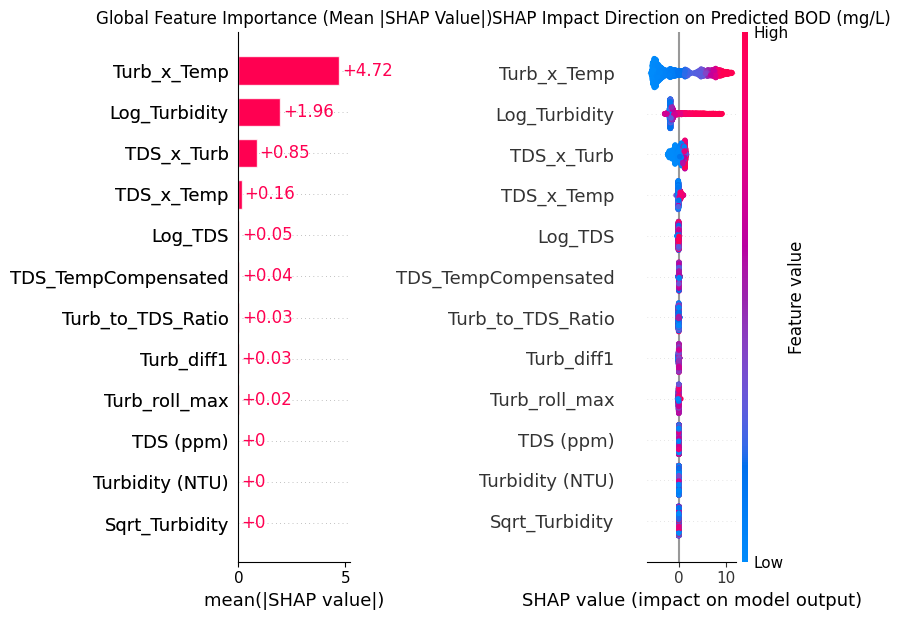


Local Waterfall Explanation for Row #13330 (Predicted BOD: 28.0 mg/L, Confidence: 89.3%):


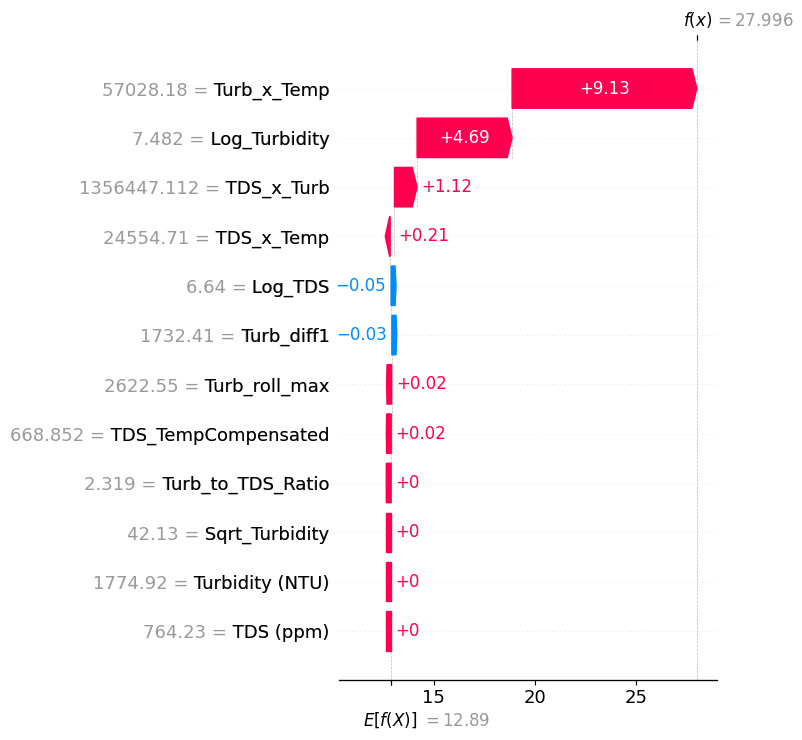

In [ ]:
# === XAI (SHAP) + PER-PREDICTION CONFIDENCE ENGINE ===
explainer = shap.TreeExplainer(gb_mi)

def predict_bod_with_xai_and_confidence(X_samples, meta_df=None, y_actual=None, top_drivers=3):
    """
    Returns BOD predictions alongside:
      - Calibrated 90% Prediction Intervals [Lower, Upper]
      - Uncertainty (± mg/L) and Confidence Score (0-100%)
      - Top SHAP feature contributions explaining each individual prediction
    """
    X_df = X_samples[SELECTED_MI_FEATURES].copy()
    preds = gb_mi.predict(X_df)

    # 1. Calibrated 90% Prediction Interval
    low = np.maximum(0.0, gb_mi_lower.predict(X_df) - conformal_q_hat)
    high = np.maximum(preds + 0.05, gb_mi_upper.predict(X_df) + conformal_q_hat)
    low = np.minimum(low, preds)
    half_width = (high - low) / 2.0

    # 2. Confidence Score (0 - 100%) combining interval sharpness & sensor in-distribution score
    rel_uncertainty = half_width / np.maximum(preds, 3.0)
    interval_conf = np.exp(-0.85 * rel_uncertainty)

    # Sensor domain novelty factor (Mahalanobis distance penalty if sensors drift outside training range)
    maha_dists = np.array([
        mahalanobis(row, train_feat_mean, train_feat_cov_inv) for row in X_df.values
    ])
    ood_factor = np.clip(1.0 - 0.25 * np.maximum(0.0, (maha_dists - maha_95) / maha_95), 0.50, 1.0)

    confidence_pct = np.clip(interval_conf * ood_factor * 100.0, 5.0, 99.9)
    conf_tier = np.where(confidence_pct >= 80.0, "High",
                np.where(confidence_pct >= 60.0, "Medium", "Low"))

    # 3. Local SHAP Values per Prediction
    shap_vals = explainer.shap_values(X_df)
    feature_names = np.array(SELECTED_MI_FEATURES)

    top_reasons = []
    for i in range(len(X_df)):
        row_shap = shap_vals[i]
        top_idx = np.argsort(np.abs(row_shap))[::-1][:top_drivers]
        drivers_str = ", ".join([
            f"{feature_names[idx]} ({row_shap[idx]:+.2f})" for idx in top_idx
        ])
        top_reasons.append(drivers_str)

    out = pd.DataFrame({
        "Pred_BOD (mg/L)": np.round(preds, 2),
        "90%_CI_Low": np.round(low, 2),
        "90%_CI_High": np.round(high, 2),
        "Uncertainty (±mg/L)": np.round(half_width, 2),
        "Confidence (%)": np.round(confidence_pct, 1),
        "Confidence_Tier": conf_tier,
        "Top_SHAP_Drivers (mg/L impact)": top_reasons
    })

    if y_actual is not None:
        out.insert(1, "Actual_BOD (mg/L)", np.round(np.asarray(y_actual), 2))
    if meta_df is not None:
        out = pd.concat([meta_df.reset_index(drop=True), out], axis=1)

    return out, shap_vals

# --- A. Display Per-Prediction Confidence & XAI Breakdown on Sample Test Rows ---
sample_indices = np.linspace(0, len(test_df) - 1, 10, dtype=int)
sample_report, sample_shap = predict_bod_with_xai_and_confidence(
    test_df.iloc[sample_indices],
    meta_df=test_df[['Timestamp', 'Location'] + RAW_FEATURES].iloc[sample_indices],
    y_actual=y_test[sample_indices]
)

print("=== SAMPLE TEST PREDICTIONS WITH CONFIDENCE & LOCAL SHAP EXPLANATIONS ===")
pd.set_option('display.max_colwidth', 90)
display(sample_report)

# --- B. Global SHAP Summary Plots (Sampled 2,000 test points for fast rendering) ---
X_shap_global = test_df[SELECTED_MI_FEATURES].iloc[:2000]
shap_exp_global = explainer(X_shap_global)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plt.sca(axes[0])
shap.plots.bar(shap_exp_global, max_display=12, show=False)
axes[0].set_title("Global Feature Importance (Mean |SHAP Value|)")

plt.sca(axes[1])
shap.plots.beeswarm(shap_exp_global, max_display=12, show=False)
axes[1].set_title("SHAP Impact Direction on Predicted BOD (mg/L)")
plt.tight_layout()
plt.show()

# --- C. Local SHAP Waterfall Plot for a Single High-BOD Prediction ---
high_bod_idx = int(np.argmax(sample_report["Pred_BOD (mg/L)"].values))
single_row = test_df[SELECTED_MI_FEATURES].iloc[[sample_indices[high_bod_idx]]]
single_shap_exp = explainer(single_row)

print(f"\nLocal Waterfall Explanation for Row #{sample_indices[high_bod_idx]} "
      f"(Predicted BOD: {sample_report['Pred_BOD (mg/L)'].iloc[high_bod_idx]} mg/L, "
      f"Confidence: {sample_report['Confidence (%)'].iloc[high_bod_idx]}%):")
plt.figure(figsize=(10, 5))
shap.plots.waterfall(single_shap_exp[0], max_display=12, show=False)
plt.tight_layout()
plt.show()

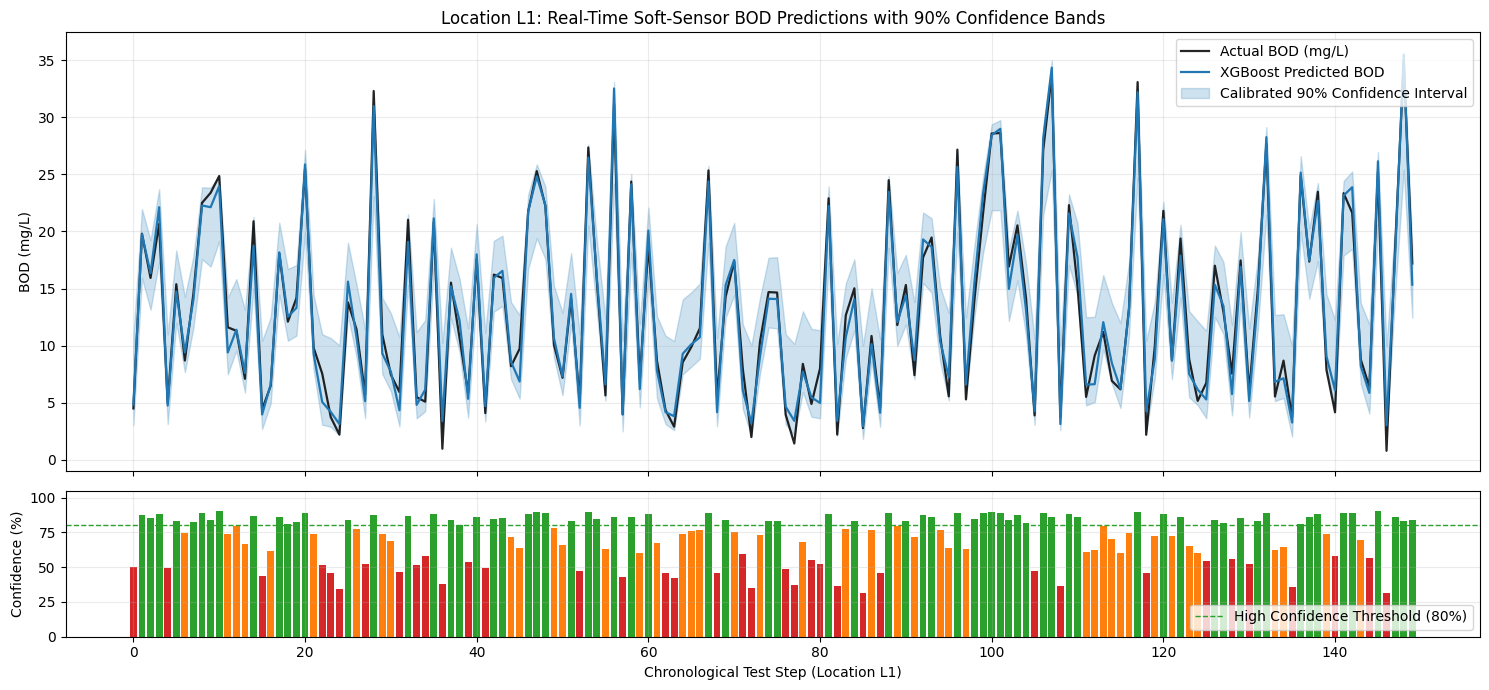

In [ ]:
# === VISUALIZING PREDICTED BOD WITH 90% CONFIDENCE BANDS ===
viz_df = test_df[test_df['Location'] == 'L1'].iloc[:150].copy()
viz_preds, _ = predict_bod_with_xai_and_confidence(
    viz_df,
    meta_df=viz_df[['Timestamp', 'Location']],
    y_actual=viz_df[TARGET_COL].values
)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 7), sharex=True, gridspec_kw={'height_ratios': [3, 1]})

x_axis = np.arange(len(viz_preds))
ax1.plot(x_axis, viz_preds['Actual_BOD (mg/L)'], label='Actual BOD (mg/L)', color='black', linewidth=1.6, alpha=0.85)
ax1.plot(x_axis, viz_preds['Pred_BOD (mg/L)'], label='XGBoost Predicted BOD', color='#1f77b4', linewidth=1.6)
ax1.fill_between(
    x_axis, viz_preds['90%_CI_Low'], viz_preds['90%_CI_High'],
    color='#1f77b4', alpha=0.22, label='Calibrated 90% Confidence Interval'
)
ax1.set_ylabel('BOD (mg/L)')
ax1.set_title('Location L1: Real-Time Soft-Sensor BOD Predictions with 90% Confidence Bands')
ax1.legend(loc='upper right')
ax1.grid(alpha=0.25)

colors = viz_preds['Confidence_Tier'].map({'High': '#2ca02c', 'Medium': '#ff7f0e', 'Low': '#d62728'})
ax2.bar(x_axis, viz_preds['Confidence (%)'], color=colors, width=0.8)
ax2.axhline(80, color='#2ca02c', linestyle='--', linewidth=1, label='High Confidence Threshold (80%)')
ax2.set_ylabel('Confidence (%)')
ax2.set_xlabel('Chronological Test Step (Location L1)')
ax2.set_ylim(0, 105)
ax2.legend(loc='lower right')
ax2.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [ ]:
import json

# Export primary XGBoost model + lower/upper quantile confidence models
gb_mi.save_model("bod_xgb.json")
gb_mi_lower.save_model("bod_xgb_lower.json")
gb_mi_upper.save_model("bod_xgb_upper.json")

# Save exact metadata & calibration constants needed by the backend
metadata = {
    "selected_features": list(SELECTED_MI_FEATURES),
    "raw_sensors": list(RAW_FEATURES),
    "window_steps": 6,
    "model_type": "XGBRegressor",
    "confidence_config": {
        "alpha": ALPHA,
        "conformal_q_hat": conformal_q_hat,
        "maha_95_threshold": maha_95,
        "train_feature_mean": train_feat_mean.tolist(),
        "train_feature_cov_inv": train_feat_cov_inv.tolist(),
        "lower_model_file": "bod_xgb_lower.json",
        "upper_model_file": "bod_xgb_upper.json"
    }
}

with open("bod_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Models exported: bod_xgb.json, bod_xgb_lower.json, bod_xgb_upper.json")
print("Metadata & confidence calibration exported: bod_metadata.json")
print("Selected features:", len(SELECTED_MI_FEATURES))

Models exported: bod_xgb.json, bod_xgb_lower.json, bod_xgb_upper.json
Metadata & confidence calibration exported: bod_metadata.json
Selected features: 12


In [ ]:
# --- E9: Regime-Specific Soft Sensor (K-Means Clustering on Raw Sensors -> Local Experts) ---
regime_scaler = RobustScaler()
X_train_reg = regime_scaler.fit_transform(train_df[RAW_FEATURES])
X_test_reg = regime_scaler.transform(test_df[RAW_FEATURES])

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
train_clusters = kmeans.fit_predict(X_train_reg)
test_clusters = kmeans.predict(X_test_reg)

pred_regime = np.zeros_like(y_test)
for c in range(3):
    tr_mask = (train_clusters == c)
    te_mask = (test_clusters == c)
    if np.sum(te_mask) == 0:
        continue
    expert = HistGradientBoostingRegressor(max_iter=200, max_depth=6, learning_rate=0.05, random_state=42)
    expert.fit(train_df.loc[tr_mask, SELECTED_MI_FEATURES], y_train[tr_mask])
    pred_regime[te_mask] = expert.predict(test_df.loc[te_mask, SELECTED_MI_FEATURES])

regime_metrics = evaluate_bod_predictions(y_test, pred_regime, "E9: Regime-Specific KMeans+GBDT")
print("=== REGIME-SPECIFIC SOFT SENSOR RESULT ===")
print(pd.DataFrame([regime_metrics]).to_string(index=False))

# --- Spatial Generalization Test: Leave-One-Location-Out Cross-Validation (GroupKFold) ---
gkf = GroupKFold(n_splits=df_engineered['Location'].nunique())
spatial_results = []

for fold, (tr_idx, val_idx) in enumerate(gkf.split(df_engineered, df_engineered[TARGET_COL], groups=df_engineered['Location'])):
    held_out_loc = df_engineered['Location'].iloc[val_idx[0]]
    model_sp = HistGradientBoostingRegressor(max_iter=200, max_depth=6, learning_rate=0.05, random_state=42)
    model_sp.fit(df_engineered.iloc[tr_idx][SELECTED_MI_FEATURES], df_engineered.iloc[tr_idx][TARGET_COL])
    preds_sp = model_sp.predict(df_engineered.iloc[val_idx][SELECTED_MI_FEATURES])
    m = evaluate_bod_predictions(df_engineered.iloc[val_idx][TARGET_COL], preds_sp, f"Unseen Location: {held_out_loc}")
    spatial_results.append(m)

spatial_df = pd.DataFrame(spatial_results)
print("\n=== SPATIAL GENERALIZATION (LEAVE-ONE-LOCATION-OUT) ===")
display(spatial_df)

=== REGIME-SPECIFIC SOFT SENSOR RESULT ===
                          Model  MAE (mg/L)  RMSE (mg/L)     R2  MAPE (%)    NSE    KGE  PBIAS (%)  Willmott_d  Reg_Class_Acc (%)  Reg_Macro_F1
E9: Regime-Specific KMeans+GBDT       0.968        1.218 0.9781     14.25 0.9781 0.9844      -0.16      0.9944              90.56        0.7196

=== SPATIAL GENERALIZATION (LEAVE-ONE-LOCATION-OUT) ===


,Model,MAE (mg/L),RMSE (mg/L),R2,MAPE (%),NSE,KGE,PBIAS (%),Willmott_d,Reg_Class_Acc (%),Reg_Macro_F1
0,Unseen Location: L4,0.970,1.220,0.9778,14.34,0.9778,0.9841,-0.02,0.9944,90.26,0.7189
1,Unseen Location: L5,0.977,1.231,0.9770,14.37,0.9770,0.9827,-0.00,0.9941,90.55,0.7193
2,Unseen Location: L2,0.965,1.214,0.9784,14.32,0.9784,0.9835,0.03,0.9945,90.50,0.7177
3,Unseen Location: L1,0.973,1.224,0.9777,14.40,0.9777,0.9819,-0.01,0.9943,90.37,0.7219
4,Unseen Location: L3,0.970,1.221,0.9777,14.04,0.9777,0.9854,0.02,0.9943,90.72,0.7240


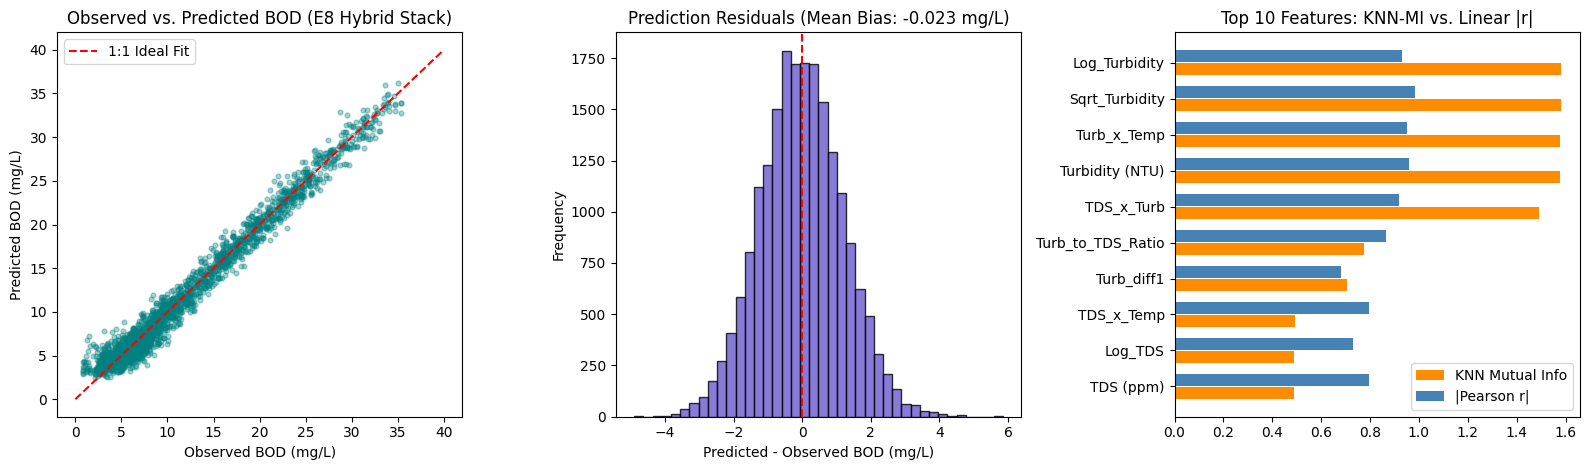

Saved trained soft-sensor artifact to 'esp32_bod_soft_sensor.joblib'


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# 1. Observed vs Predicted BOD (Hybrid Stack)
sample_plot = np.random.choice(len(y_test), size=min(2000, len(y_test)), replace=False)
axes[0].scatter(y_test[sample_plot], predictions_store["E8: Hybrid Stack"][sample_plot], alpha=0.35, s=12, color='teal')
axes[0].plot([0, 40], [0, 40], 'r--', lw=1.5, label='1:1 Ideal Fit')
axes[0].set_title('Observed vs. Predicted BOD (E8 Hybrid Stack)')
axes[0].set_xlabel('Observed BOD (mg/L)')
axes[0].set_ylabel('Predicted BOD (mg/L)')
axes[0].legend()

# 2. Residual Error Distribution
residuals = predictions_store["E8: Hybrid Stack"] - y_test
axes[1].hist(residuals, bins=40, color='slateblue', edgecolor='black', alpha=0.8)
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_title(f'Prediction Residuals (Mean Bias: {np.mean(residuals):.3f} mg/L)')
axes[1].set_xlabel('Predicted - Observed BOD (mg/L)')
axes[1].set_ylabel('Frequency')

# 3. Top 10 KNN Mutual Information vs Linear Pearson |r|
top10_mi = mi_report.head(10).iloc[::-1]
y_pos = np.arange(len(top10_mi))
axes[2].barh(y_pos - 0.18, top10_mi['KNN_MI'], height=0.35, label='KNN Mutual Info', color='darkorange')
axes[2].barh(y_pos + 0.18, top10_mi['Abs_Pearson_r'], height=0.35, label='|Pearson r|', color='steelblue')
axes[2].set_yticks(y_pos)
axes[2].set_yticklabels(top10_mi['Feature'])
axes[2].set_title('Top 10 Features: KNN-MI vs. Linear |r|')
axes[2].legend()

plt.tight_layout()
plt.show()

# Save production artifact for ESP32 MQTT inference server
artifact = {
    'model': gb_mi,
    'selected_features': SELECTED_MI_FEATURES,
    'raw_sensors': RAW_FEATURES,
    'window_steps': 6
}
joblib.dump(artifact, 'esp32_bod_soft_sensor.joblib')
print("Saved trained soft-sensor artifact to 'esp32_bod_soft_sensor.joblib'")